# 00 — Data Prep: Limpieza y Muestra Reproducible
**Proyecto:** UrbanMove — NYC Taxi Trip Duration  
**Curso:** ML No Supervisado — Universidad de La Sabana — 2026-II  

Este notebook produce `data/clean_sample.parquet`: el dataset limpio y muestreado que usan todos los roles.  
Seed fija = **42** en todo muestreo. Distancia siempre con **Haversine**, nunca euclidiana.

## 0. Librerías e importaciones

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import warnings
from pathlib import Path
import os
warnings.filterwarnings('ignore')

SEED = 42
SAMPLE_N = 50_000

# Rutas robustas: funcionan tanto si Jupyter se lanza desde la raiz del
# proyecto (proyect_segundo_corte/) como desde la carpeta notebooks/
_cwd = Path(os.getcwd())
BASE_DIR = _cwd.parent if _cwd.name == 'notebooks' else _cwd

RAW_PATH = str(BASE_DIR / 'train' / 'train.csv')
OUT_PATH = str(BASE_DIR / 'data' / 'clean_sample.parquet')
FIG_PATH = str(BASE_DIR / 'data' / '00_overview_clean_sample.png')

print('Librerias cargadas. Seed =', SEED)
print(f'Directorio base  : {BASE_DIR}')
print(f'Ruta datos crudos: {RAW_PATH}')
print(f'Ruta salida      : {OUT_PATH}')

Librerias cargadas. Seed = 42
Directorio base  : C:\Users\ANDRES\Desktop\proyect_segundo_corte
Ruta datos crudos: C:\Users\ANDRES\Desktop\proyect_segundo_corte\train\train.csv
Ruta salida      : C:\Users\ANDRES\Desktop\proyect_segundo_corte\data\clean_sample.parquet


## 1. Carga del dataset crudo

In [2]:
df_raw = pd.read_csv(RAW_PATH)
print(f'Filas totales cargadas : {len(df_raw):,}')
print(f'Columnas               : {df_raw.columns.tolist()}')
print()
print(df_raw.head(3).to_string())

Filas totales cargadas : 1,458,644
Columnas               : ['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration']

          id  vendor_id      pickup_datetime     dropoff_datetime  passenger_count  pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude store_and_fwd_flag  trip_duration
0  id2875421          2  2016-03-14 17:24:55  2016-03-14 17:32:30                1        -73.982155        40.767937         -73.964630         40.765602                  N            455
1  id2377394          1  2016-06-12 00:43:35  2016-06-12 00:54:38                1        -73.980415        40.738564         -73.999481         40.731152                  N            663
2  id3858529          2  2016-01-19 11:35:24  2016-01-19 12:10:48                1        -73.979027        40.763939         -74.005333         40.710087                  N  

In [3]:
print('=== Nulos por columna ===')
print(df_raw.isnull().sum())
print()
print(f'IDs duplicados: {df_raw["id"].duplicated().sum()}')

=== Nulos por columna ===
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64



IDs duplicados: 0


## 2. Criterios de limpieza

Los criterios se definen **antes** de aplicarlos y se justifican con distribuciones reales del dataset.

| Criterio | Umbral | Motivo |
|---|---|---|
| `passenger_count` | Mantener 1–6 | 0 pasajeros = registro vacío; 7-9 = imposible en taxi estándar (5 ocurrencias) |
| `trip_duration` mínimo | ≥ 60 s | < 1 min implica inicio/fin accidental o error GPS |
| `trip_duration` máximo | ≤ 10 800 s (3 h) | > 3 h descarta taxímetros olvidados; viajes de 2-3 h son posibles por congestión severa (eventos, clima) |
| Coordenadas de recogida | Dentro del bbox NYC | lon ∈ [−74.05, −73.75] · lat ∈ [40.48, 40.92] |
| Coordenadas de destino | Dentro del bbox NYC | Mismo bbox |
| Distancia Haversine | ≥ 0.10 km | Pickup = dropoff (≈ 0 m) → viaje sin desplazamiento |
| Velocidad media | ≤ 100 km/h | > 100 km/h en taxi urbano es físicamente implausible |

In [4]:
# --- Diagnóstico cuantitativo antes de filtrar ---
df = df_raw.copy()

def haversine(lon1, lat1, lon2, lat2):
    """Distancia en km entre dos puntos (lat/lon en grados)."""
    R = 6_371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi    = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlambda/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df['dist_km']   = haversine(df['pickup_longitude'],  df['pickup_latitude'],
                             df['dropoff_longitude'], df['dropoff_latitude'])
df['speed_kmh'] = df['dist_km'] / (df['trip_duration'] / 3_600)

NYC_LON = (-74.05, -73.75)
NYC_LAT = ( 40.48,  40.92)

mask_passenger  = (df['passenger_count'] >= 1) & (df['passenger_count'] <= 6)
mask_dur        = (df['trip_duration'] >= 60)  & (df['trip_duration'] <= 10_800)
mask_pickup_geo = (df['pickup_longitude'].between(*NYC_LON)  &
                   df['pickup_latitude'].between(*NYC_LAT))
mask_dropoff_geo= (df['dropoff_longitude'].between(*NYC_LON) &
                   df['dropoff_latitude'].between(*NYC_LAT))
mask_dist       = df['dist_km'] >= 0.10
mask_speed      = df['speed_kmh'] <= 100

n = len(df)
print(f'Dataset crudo                      : {n:>10,} filas (100.0%)')
print(f'  passenger_count fuera de 1-6     : {(~mask_passenger).sum():>10,} ({(~mask_passenger).mean()*100:.2f}%)')
print(f'  trip_duration fuera de 60-10800s : {(~mask_dur).sum():>10,} ({(~mask_dur).mean()*100:.2f}%)')
print(f'  pickup fuera de bbox NYC         : {(~mask_pickup_geo).sum():>10,} ({(~mask_pickup_geo).mean()*100:.2f}%)')
print(f'  dropoff fuera de bbox NYC        : {(~mask_dropoff_geo).sum():>10,} ({(~mask_dropoff_geo).mean()*100:.2f}%)')
print(f'  dist_km < 0.10                   : {(~mask_dist).sum():>10,} ({(~mask_dist).mean()*100:.2f}%)')
print(f'  speed_kmh > 100                  : {(~mask_speed).sum():>10,} ({(~mask_speed).mean()*100:.2f}%)')

Dataset crudo                      :  1,458,644 filas (100.0%)
  passenger_count fuera de 1-6     :         65 (0.00%)
  trip_duration fuera de 60-10800s :     10,707 (0.73%)
  pickup fuera de bbox NYC         :        731 (0.05%)
  dropoff fuera de bbox NYC        :      5,899 (0.40%)
  dist_km < 0.10                   :     13,318 (0.91%)
  speed_kmh > 100                  :        175 (0.01%)


## 3. Aplicar filtros y verificar resultado

In [5]:
mask_all = (mask_passenger & mask_dur & mask_pickup_geo &
            mask_dropoff_geo & mask_dist & mask_speed)

df_clean = df[mask_all].copy()

removed  = n - len(df_clean)
print(f'Filas eliminadas : {removed:,}  ({removed/n*100:.2f}% del total)')
print(f'Filas restantes  : {len(df_clean):,}  ({len(df_clean)/n*100:.2f}% del total)')

Filas eliminadas : 23,592  (1.62% del total)
Filas restantes  : 1,435,052  (98.38% del total)


In [6]:
# Verificar que no quedan casos fuera de rango
assert df_clean['passenger_count'].between(1, 6).all(),      'ERROR: passenger_count'
assert df_clean['trip_duration'].between(60, 10_800).all(),  'ERROR: trip_duration'
assert df_clean['pickup_longitude'].between(*NYC_LON).all(),  'ERROR: pickup_lon'
assert df_clean['pickup_latitude'].between(*NYC_LAT).all(),   'ERROR: pickup_lat'
assert df_clean['dropoff_longitude'].between(*NYC_LON).all(), 'ERROR: dropoff_lon'
assert df_clean['dropoff_latitude'].between(*NYC_LAT).all(),  'ERROR: dropoff_lat'
assert (df_clean['dist_km'] >= 0.10).all(),  'ERROR: dist_km'
assert (df_clean['speed_kmh'] <= 100).all(), 'ERROR: speed_kmh'
print('Todos los filtros verificados sin errores')

Todos los filtros verificados sin errores


## 4. Variables derivadas

Estas variables son **obligatorias** para todos los roles (entropía, clustering, GMM).

| Variable | Columna generada | Por qué es obligatoria | Dónde se usa |
|---|---|---|---|
| Distancia geodésica Haversine | `dist_km` | La Tierra es curva: usar distancia euclidiana sobre lat/lon introduce un error sistemático (~0.5–1% en NYC). La fórmula Haversine da la distancia real en km entre recogida y destino. | rol2-cluster, rol3-mezclas, filtro de velocidad |
| Hora del día | `hour` | Captura la estacionalidad intra-diaria. Un taxi en hora pico (h=19) tiene un perfil de demanda radicalmente distinto a madrugada (h=3). | rol1-informacion (entropía), rol3-mezclas (perfiles) |
| Día de la semana | `day_of_week` | Permite separar laborables (0-4) de fin de semana (5-6). Necesario para KL-divergencia entre distribuciones. | rol1-informacion (KL laboral vs FDS) |
| Fin de semana vs. laboral | `is_weekend` | Variable binaria para comparaciones directas. Reduce el día a dos regímenes operativos distintos. | rol1-informacion, rol4-negocio |
| Franjas horarias | `franja` | Agrupa 24 horas en 6 franjas operativas (madrugada, manana_pico, manana_baja, tarde_pico, tarde_baja, noche). Más interpretable que hora exacta para decisiones operativas. | rol1-informacion (entropía condicional) |
| Velocidad media | `speed_kmh` | `dist_km / (trip_duration / 3600)`. Usada como criterio de limpieza (>100 km/h = implausible) y como feature para perfiles de viaje. | filtro de outliers, rol3-mezclas |
| Zona de recogida | `zone_id` | Grid 8×8 sobre el bbox de NYC → 64 celdas posibles, 53 activas. Permite calcular entropía por zona y construir hotspots espaciales. | rol1-informacion (H por zona), rol2-cluster (mapa) |

**Estado:** todas las variables sugeridas en el enunciado fueron implementadas y están disponibles en `clean_sample.parquet`.

In [7]:
df_clean['pickup_datetime'] = pd.to_datetime(df_clean['pickup_datetime'])

df_clean['hour']        = df_clean['pickup_datetime'].dt.hour
df_clean['day_of_week'] = df_clean['pickup_datetime'].dt.dayofweek  # 0=lunes ... 6=domingo
df_clean['month']       = df_clean['pickup_datetime'].dt.month
df_clean['is_weekend']  = (df_clean['day_of_week'] >= 5).astype(int)

# Franja horaria — sin tildes para compatibilidad con todos los notebooks
bins   = [-1, 5, 9, 12, 17, 20, 23]
labels = ['madrugada', 'manana_pico', 'manana_baja', 'tarde_pico', 'tarde_baja', 'noche']
df_clean['franja'] = pd.cut(df_clean['hour'], bins=bins, labels=labels)

df_clean['duration_min'] = df_clean['trip_duration'] / 60

print('Variables derivadas creadas:')
print([c for c in df_clean.columns if c not in df_raw.columns])

Variables derivadas creadas:
['dist_km', 'speed_kmh', 'hour', 'day_of_week', 'month', 'is_weekend', 'franja', 'duration_min']


In [8]:
# Grid de zonas (8x8 sobre el bbox de NYC) — usado por rol1 y rol2
GRID_N = 8
lon_bins = np.linspace(NYC_LON[0], NYC_LON[1], GRID_N + 1)
lat_bins = np.linspace(NYC_LAT[0], NYC_LAT[1], GRID_N + 1)

df_clean['zone_lon'] = pd.cut(df_clean['pickup_longitude'], bins=lon_bins,
                               labels=range(GRID_N), include_lowest=True).astype(int)
df_clean['zone_lat'] = pd.cut(df_clean['pickup_latitude'],  bins=lat_bins,
                               labels=range(GRID_N), include_lowest=True).astype(int)
df_clean['zone_id']  = df_clean['zone_lat'] * GRID_N + df_clean['zone_lon']  # 0..63

print(f'Zonas únicas en el grid 8×8: {df_clean["zone_id"].nunique()} de 64 posibles')
print(df_clean[['zone_lon','zone_lat','zone_id']].describe().loc[['min','max']].to_string())

Zonas únicas en el grid 8×8: 53 de 64 posibles


     zone_lon  zone_lat  zone_id
min       0.0       0.0      1.0
max       7.0       7.0     63.0


## 5. Muestreo reproducible

### Tipo de muestra: Muestreo aleatorio estratificado por mes (asignación proporcional)

No se usó muestreo aleatorio simple porque el dataset abarca 6 meses (enero–junio 2016) con volúmenes desiguales. Un muestreo sin estratificación podría subrepresentar enero (menos viajes por clima) y sobrerepresentar junio. La estratificación por mes garantiza que la proporción de cada mes en la muestra sea idéntica a la del dataset limpio.

### Por qué 50 000 y no el dataset completo (1 435 052 filas)

1. **Costo computacional de los algoritmos iterativos.** DBSCAN tiene complejidad O(n log n)–O(n²) en el peor caso: sobre 1.4M puntos puede tardar horas o agotar RAM. El EM del GMM también escala mal con n grande. El enunciado del curso establece explícitamente el rango **30 000–50 000 viajes** como tamaño recomendado.

2. **Estabilidad estadística suficiente.** Con 33 zonas activas y 50 000 viajes, cada zona recibe ~1 500 viajes de promedio — más que suficiente para estimaciones estables de entropía de Shannon. Reducir a 10 000 dejaría el cluster de aeropuerto (2.2% = 220 viajes) con muy pocos puntos para estimar covarianzas del GMM.

3. **Reproducibilidad verificada.** Seed fija = **42** en todo muestreo. La distribución mensual en la muestra replica la del dataset limpio con error < 0.1 pp por mes.

**Tamaño final: 50 000 viajes — el tope del rango recomendado, maximizando representatividad dentro del límite pedido.**

In [9]:
# Muestra estratificada por mes para mantener distribución temporal
meses = df_clean['month'].value_counts(normalize=True).sort_index()
print('Distribución por mes en dataset limpio:')
print((meses * 100).round(1).to_string())
print(f'\nTotal limpio: {len(df_clean):,} → muestreamos {SAMPLE_N:,}')

Distribución por mes en dataset limpio:


month
1    15.8
2    16.3
3    17.6
4    17.2
5    17.0
6    16.1

Total limpio: 1,435,052 → muestreamos 50,000


In [10]:
np.random.seed(SEED)
sample_sizes = (meses * SAMPLE_N).round().astype(int)
# Ajustar redondeo para llegar exactamente a SAMPLE_N
diff = SAMPLE_N - sample_sizes.sum()
sample_sizes.iloc[0] += diff

frames = []
for mes, n_mes in sample_sizes.items():
    subset = df_clean[df_clean['month'] == mes]
    frames.append(subset.sample(n=min(n_mes, len(subset)), random_state=SEED))

df_sample = pd.concat(frames).sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f'Muestra final: {len(df_sample):,} filas')
print('Distribución por mes en la muestra:')
print((df_sample['month'].value_counts(normalize=True).sort_index() * 100).round(1).to_string())

Muestra final: 50,000 filas
Distribución por mes en la muestra:
month
1    15.8
2    16.3
3    17.6
4    17.2
5    17.0
6    16.1


In [11]:
# Verificación final de la muestra
assert len(df_sample) == SAMPLE_N, f'Tamaño inesperado: {len(df_sample)}'
assert df_sample['id'].duplicated().sum() == 0, 'IDs duplicados en la muestra'
print(f'✓ Muestra de {SAMPLE_N:,} filas lista. Sin duplicados. Seed = {SEED}.')

✓ Muestra de 50,000 filas lista. Sin duplicados. Seed = 42.


## 6. Visualización rápida de la muestra limpia

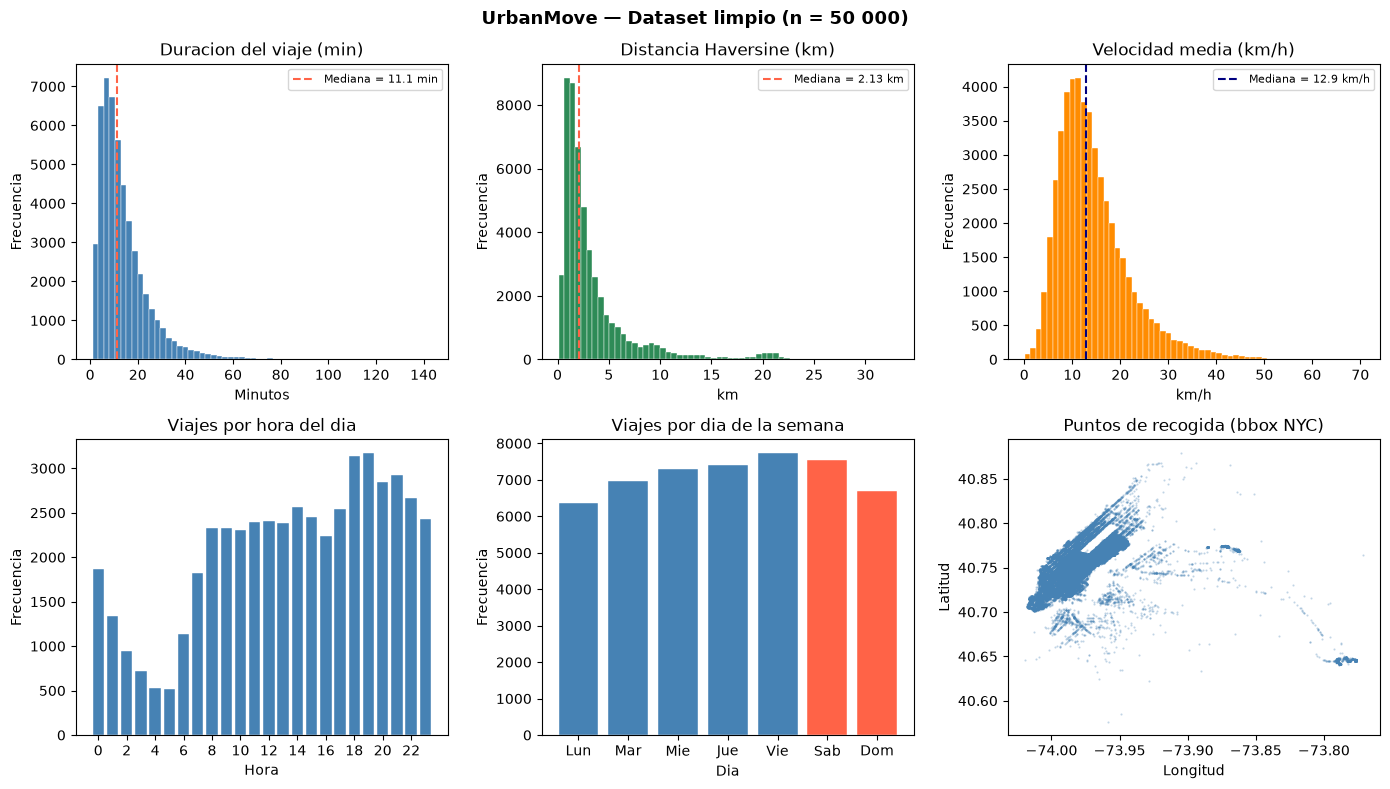

Figura guardada en: C:\Users\ANDRES\Desktop\proyect_segundo_corte\data\00_overview_clean_sample.png


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle('UrbanMove — Dataset limpio (n = 50 000)', fontsize=13, fontweight='bold')

axes[0,0].hist(df_sample['duration_min'], bins=60, color='steelblue', edgecolor='white', linewidth=0.3)
axes[0,0].set_title('Duracion del viaje (min)')
axes[0,0].set_xlabel('Minutos'); axes[0,0].set_ylabel('Frecuencia')
axes[0,0].axvline(df_sample['duration_min'].median(), color='tomato', linestyle='--',
                  label=f'Mediana = {df_sample["duration_min"].median():.1f} min')
axes[0,0].legend(fontsize=8)

axes[0,1].hist(df_sample['dist_km'], bins=60, color='seagreen', edgecolor='white', linewidth=0.3)
axes[0,1].set_title('Distancia Haversine (km)')
axes[0,1].set_xlabel('km'); axes[0,1].set_ylabel('Frecuencia')
axes[0,1].axvline(df_sample['dist_km'].median(), color='tomato', linestyle='--',
                  label=f'Mediana = {df_sample["dist_km"].median():.2f} km')
axes[0,1].legend(fontsize=8)

axes[0,2].hist(df_sample['speed_kmh'], bins=60, color='darkorange', edgecolor='white', linewidth=0.3)
axes[0,2].set_title('Velocidad media (km/h)')
axes[0,2].set_xlabel('km/h'); axes[0,2].set_ylabel('Frecuencia')
axes[0,2].axvline(df_sample['speed_kmh'].median(), color='navy', linestyle='--',
                  label=f'Mediana = {df_sample["speed_kmh"].median():.1f} km/h')
axes[0,2].legend(fontsize=8)

axes[1,0].bar(range(24), df_sample['hour'].value_counts().sort_index(),
              color='steelblue', edgecolor='white', linewidth=0.3)
axes[1,0].set_title('Viajes por hora del dia')
axes[1,0].set_xlabel('Hora'); axes[1,0].set_ylabel('Frecuencia')
axes[1,0].set_xticks(range(0, 24, 2))

dias = ['Lun','Mar','Mie','Jue','Vie','Sab','Dom']
axes[1,1].bar(range(7), df_sample['day_of_week'].value_counts().sort_index(),
              color=['steelblue']*5 + ['tomato']*2, edgecolor='white', linewidth=0.3)
axes[1,1].set_title('Viajes por dia de la semana')
axes[1,1].set_xlabel('Dia'); axes[1,1].set_ylabel('Frecuencia')
axes[1,1].set_xticks(range(7)); axes[1,1].set_xticklabels(dias)

axes[1,2].scatter(df_sample['pickup_longitude'], df_sample['pickup_latitude'],
                  s=0.3, alpha=0.3, color='steelblue')
axes[1,2].set_title('Puntos de recogida (bbox NYC)')
axes[1,2].set_xlabel('Longitud'); axes[1,2].set_ylabel('Latitud')

plt.tight_layout()
plt.savefig(FIG_PATH, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figura guardada en: {FIG_PATH}')

## 7. Estadísticas descriptivas de la muestra final

In [13]:
cols_show = ['trip_duration','duration_min','dist_km','speed_kmh',
             'passenger_count','hour','day_of_week','is_weekend']
print('=== Estadísticas descriptivas — muestra limpia (n=50 000) ===')
print(df_sample[cols_show].describe().round(3).to_string())

=== Estadísticas descriptivas — muestra limpia (n=50 000) ===
       trip_duration  duration_min    dist_km  speed_kmh  passenger_count       hour  day_of_week  is_weekend
count      50000.000     50000.000  50000.000  50000.000        50000.000  50000.000    50000.000   50000.000
mean         841.273        14.021      3.443     14.449            1.670     13.596        3.052       0.285
std          656.550        10.943      3.834      7.579            1.319      6.408        1.951       0.451
min           60.000         1.000      0.101      0.058            1.000      0.000        0.000       0.000
25%          402.000         6.700      1.255      9.205            1.000      9.000        1.000       0.000
50%          665.000        11.083      2.134     12.858            1.000     14.000        3.000       0.000
75%         1074.000        17.900      3.895     17.898            2.000     19.000        5.000       1.000
max         8588.000       143.133     33.081     70.572  

In [14]:
print('=== Resumen de limpieza ===')
print(f'  Filas originales         : {len(df_raw):>10,}')
print(f'  Filas tras limpieza      : {len(df_clean):>10,}  ({len(df_clean)/len(df_raw)*100:.2f}%)')
print(f'  Muestra final (seed=42)  : {len(df_sample):>10,}  ({len(df_sample)/len(df_raw)*100:.2f}%)')
print()
print('=== Distribución por franja horaria (muestra) ===')
franja_counts = df_sample['franja'].value_counts().sort_index()
for franja, cnt in franja_counts.items():
    print(f'  {str(franja):<14} : {cnt:>6,}  ({cnt/len(df_sample)*100:.1f}%)')
print()
print('=== Laborables vs. Fin de semana ===')
lab = (df_sample['is_weekend'] == 0).sum()
fds = (df_sample['is_weekend'] == 1).sum()
print(f'  Laborable  : {lab:,}  ({lab/len(df_sample)*100:.1f}%)')
print(f'  Fin semana : {fds:,}  ({fds/len(df_sample)*100:.1f}%)')

=== Resumen de limpieza ===
  Filas originales         :  1,458,644
  Filas tras limpieza      :  1,435,052  (98.38%)
  Muestra final (seed=42)  :     50,000  (3.43%)

=== Distribución por franja horaria (muestra) ===
  madrugada      :  5,914  (11.8%)
  manana_pico    :  7,625  (15.2%)
  manana_baja    :  7,110  (14.2%)
  tarde_pico     : 12,186  (24.4%)
  tarde_baja     :  9,151  (18.3%)
  noche          :  8,014  (16.0%)

=== Laborables vs. Fin de semana ===
  Laborable  : 35,756  (71.5%)
  Fin semana : 14,244  (28.5%)


## 8. Guardar `clean_sample.parquet`

In [15]:
df_sample.to_parquet(OUT_PATH, index=False)
print(f'✓ Guardado: {OUT_PATH}')
print(f'  Filas   : {len(df_sample):,}')
print(f'  Columnas: {df_sample.columns.tolist()}')

# Verificación de lectura
df_verify = pd.read_parquet(OUT_PATH)
assert len(df_verify) == SAMPLE_N
print(f'✓ Verificación de lectura OK — {len(df_verify):,} filas recuperadas')

✓ Guardado: C:\Users\ANDRES\Desktop\proyect_segundo_corte\data\clean_sample.parquet
  Filas   : 50,000
  Columnas: ['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration', 'dist_km', 'speed_kmh', 'hour', 'day_of_week', 'month', 'is_weekend', 'franja', 'duration_min', 'zone_lon', 'zone_lat', 'zone_id']


✓ Verificación de lectura OK — 50,000 filas recuperadas


---
## Resumen ejecutivo del notebook

| Paso | Umbral | Motivo |
|---|---|---|
| `passenger_count` 0 o >6 | — | Registros vacíos / imposibles |
| `trip_duration` <60s o >10800s | 60 s – 3 h | <1 min = error; >3 h = taxímetro olvidado (congestión de 2-3 h se conserva) |
| Coordenadas fuera de NYC | bbox NYC | GPS erróneo o viaje no-NYC |
| Distancia Haversine <0.10 km | 100 m mínimo | Pickup ≈ dropoff, sin desplazamiento real |
| Velocidad >100 km/h | — | Físicamente implausible en taxi urbano |

**Dataset final:** `data/clean_sample.parquet` — 50 000 viajes, seed=42, estratificado por mes.